# RQ3 - VAR mo rong + Impulse Response

Muc tieu: quan he dong giua Level/Slope/Curvature va bien vi mo (CPI YoY, Fed funds rate), phan tich co che truyen dan qua IRF.

In [1]:
import sys
sys.path.append('..')

from src import config, data_fetch, var_analysis as va
import pandas as pd

## 1. Nap factor + du lieu vi mo

In [2]:
from src.utils import ensure_monthly_freq, resample_to_monthly

factors_monthly = pd.read_csv('../data/ns_factors_monthly.csv', index_col=0, parse_dates=True)
factors_monthly = ensure_monthly_freq(factors_monthly)

_, macro, _ = data_fetch.fetch_fred_data()
macro_monthly = resample_to_monthly(macro)
macro_monthly['cpi_yoy'] = data_fetch.compute_cpi_yoy(macro_monthly)
var_input = ensure_monthly_freq(macro_monthly[['cpi_yoy', 'fed_funds']])

## 2. Kiem dinh stationarity (ADF/KPSS) truoc khi fit VAR

ADF (H0: unit root) + KPSS (H0: stationary). Cot `kpss_note` ghi khi statistic nam ngoai bang look-up cua statsmodels — p-value tra ve la **can** (0.01 / 0.10), khong phai loi tinh toan.

In [3]:
data_check = factors_monthly.join(var_input, how='inner').dropna()
va.test_stationarity_all(data_check)

,series,adf_stat,adf_pvalue,kpss_stat,kpss_pvalue,kpss_note,likely_stationary
0,level,-1.230752,0.904010,1.491324,0.010000,p_actual<reported (stat outside table),False
1,slope,-4.003016,0.008707,0.767941,0.010000,p_actual<reported (stat outside table),False
2,curvature,-2.723461,0.226471,0.347605,0.099739,,False
3,cpi_yoy,-3.314163,0.063957,0.312752,0.100000,p_actual>reported (stat outside table),False
4,fed_funds,-3.668114,0.024545,0.378866,0.086264,,True


## 3. Fit VAR + kiem tra stability

In [4]:
var_results, var_data = va.fit_var_model(factors_monthly, var_input)
print(var_results.summary())
va.check_var_stability(var_results)

  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Tue, 29, Sep, 2026
Time:                     17:37:43
--------------------------------------------------------------------
No. of Equations:         5.00000    BIC:                   -12.1931
Nobs:                     315.000    HQIC:                  -12.9442
Log likelihood:          -12.3995    FPE:                1.45137e-06
AIC:                     -13.4440    Det(Omega_mle):     1.05108e-06
--------------------------------------------------------------------
Results for equation cpi_yoy
                  coefficient       std. error           t-stat            prob
-------------------------------------------------------------------------------
const                0.047082         0.075408            0.624           0.532
L1.cpi_yoy           0.505662         0.060096            8.414           0.000
L1.fed_funds         0.333963         0.277360            1.20

{'is_stable': True,
 'roots': array([-2.29573847+1.89946721j, -2.29573847-1.89946721j,
        -0.37291443-2.34925644j, -0.37291443+2.34925644j,
         1.33535611+1.84690313j,  1.33535611-1.84690313j,
        -2.17751185-0.j        ,  1.67064459+0.58556419j,
         1.67064459-0.58556419j, -0.48603906-1.6860905j ,
        -0.48603906+1.6860905j , -1.06651951-1.231246j  ,
        -1.06651951+1.231246j  ,  0.9580822 +1.27843508j,
         0.9580822 -1.27843508j, -0.47798474+1.47177935j,
        -0.47798474-1.47177935j,  1.14263213-0.j        ,
         1.04085649+0.02355435j,  1.04085649-0.02355435j])}

## 4. Granger causality

In [5]:
va.run_granger_causality_matrix(var_results, list(var_data.columns))

,caused,causing,test_stat,p_value,conclusion
0,cpi_yoy,fed_funds,1.566670,1.807179e-01,fail to reject
1,cpi_yoy,level,0.540594,7.059447e-01,fail to reject
2,cpi_yoy,slope,0.320515,8.643591e-01,fail to reject
3,cpi_yoy,curvature,2.053212,8.467174e-02,fail to reject
4,fed_funds,cpi_yoy,1.987353,9.404915e-02,fail to reject
5,fed_funds,level,31.622694,2.651558e-25,reject
6,fed_funds,slope,36.338694,5.349162e-29,reject
7,fed_funds,curvature,11.759485,2.100127e-09,reject
8,level,cpi_yoy,1.281762,2.750457e-01,fail to reject
9,level,fed_funds,0.760444,5.510378e-01,fail to reject


## 5. Impulse Response Function

Cholesky ordering da chot trong `fit_var_model`: `cpi_yoy`, `fed_funds` (vi mo, phan ung cham) dung TRUOC `level`, `slope`, `curvature` (tai chinh, phan ung nhanh trong cung thang).

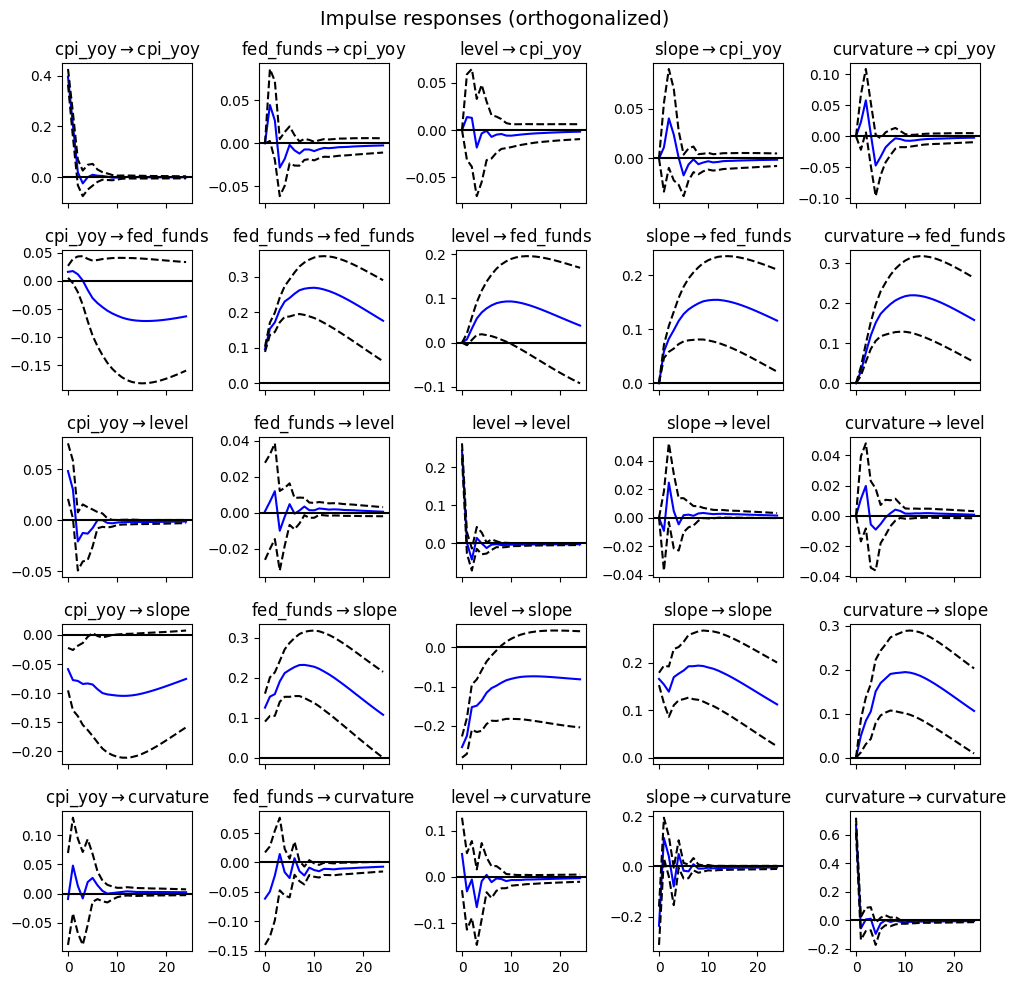

In [6]:
from pathlib import Path
Path('../outputs').mkdir(exist_ok=True)
irf = va.plot_impulse_response(var_results, periods=24, save_path='../outputs/rq3_irf_full.png')

## 6. Xuat ket qua

In [7]:
var_data.to_csv('../data/var_input_data.csv')